Gene region length: 1843
GC %: 64.6
Naive protein length (wrong because of introns): 31
Coding sequence length: 333
Protein length: 110
MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN
MATCH with UniProt reference
Example mutation (position 100 -> A): (34, 'H', 'N', 'missense')
Total possible single-base mutations: 999
type
missense      687
silent        255
nonsense       40
start_loss      9
stop_loss       8
Name: count, dtype: int64
type
missense      68.8
silent        25.5
nonsense       4.0
start_loss     0.9
stop_loss      0.8
Name: count, dtype: float64


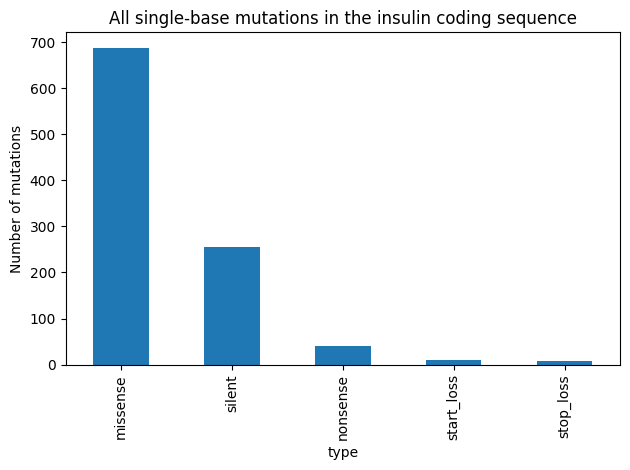

Saved: insulin_all_mutations.csv


In [6]:
# ===== Insulin Gene Mutation Explorer =====
import pandas as pd
import matplotlib.pyplot as plt

# 1) تسلسل جين الإنسولين البشري (INS) من NCBI
dna = """
CAGCGCAAAGAGCCCCGCCCTGCAGCCTCCAGCTCTCCTGGTCTAATGTGGAAAGTGGCCCAGGTGAGGG
CTTTGCTCTCCTGGAGACATTTGCCCCCAGCTGTGAGCAGGGACAGGTCTGGCCACCGGGCCCCTGGTTA
AGACTCTAATGACCCGCTGGTCCTGAGGAAGAGGTGCTGACGACCAAGGAGATCTTCCCACAGACCCAGC
ACCAGGGAAATGGTCCGGAAATTGCAGCCTCAGCCCCCAGCCATCTGCCGACCCCCCCACCCCAGGCCCT
AATGGGCCAGGCGGCAGGGGTTGACAGGTAGGGGAGATGGGCTCTGAGACTATAAAGCCAGCGGGGGCCC
AGCAGCCCTCAGCCCTCCAGGACAGGCTGCATCAGAAGAGGCCATCAAGCAGGTCTGTTCCAAGGGCCTT
TGCGTCAGGTGGGCTCAGGGTTCCAGGGTGGCTGGACCCCAGGCCCCAGCTCTGCAGCAGGGAGGACGTG
GCTGGGCTCGTGAAGCATGTGGGGGTGAGCCCAGGGGCCCCAAGGCAGGGCACCTGGCCTTCAGCCTGCC
TCAGCCCTGCCTGTCTCCCAGATCACTGTCCTTCTGCCATGGCCCTGTGGATGCGCCTCCTGCCCCTGCT
GGCGCTGCTGGCCCTCTGGGGACCTGACCCAGCCGCAGCCTTTGTGAACCAACACCTGTGCGGCTCACAC
CTGGTGGAAGCTCTCTACCTAGTGTGCGGGGAACGAGGCTTCTTCTACACACCCAAGACCCGCCGGGAGG
CAGAGGACCTGCAGGGTGAGCCAACCGCCCATTGCTGCCCCTGGCCGCCCCCAGCCACCCCCTGCTCCTG
GCGCTCCCACCCAGCATGGGCAGAAGGGGGCAGGAGGCTGCCACCCAGCAGGGGGTCAGGTGCACTTTTT
TAAAAAGAAGTTCTCTTGGTCACGTCCTAAAAGTGACCAGCTCCCTGTGGCCCAGTCAGAATCTCAGCCT
GAGGACGGTGTTGGCTTCGGCAGCCCCGAGATACATCAGAGGGTGGGCACGCTCCTCCCTCCACTCGCCC
CTCAAACAAATGCCCCGCAGCCCATTTCTCCACCCTCATTTGATGACCGCAGATTCAAGTGTTTTGTTAA
GTAAAGTCCTGGGTGACCTGGGGTCACAGGGTGCCCCACGCTGCCTGCCTCTGGGCGAACACCCCATCAC
GCCCGGAGGAGGGCGTGGCTGCCTGCCTGAGTGGGCCAGACCCCTGTCGCCAGGCCTCACGGCAGCTCCA
TAGTCAGGAGATGGGGAAGATGCTGGGGACAGGCCCTGGGGAGAAGTACTGGGATCACCTGTTCAGGCTC
CCACTGTGACGCTGCCCCGGGGCGGGGGAAGGAGGTGGGACATGTGGGCGTTGGGGCCTGTAGGTCCACA
CCCACTGTGGGTGACCCTCCCTCTAACCTGGGTCCAGCCCGGCTGGAGATGGGTGGGAGTGTGACCTAGG
GCTGGCGGGCAGGCGGGCACTGTGTCTCCCTGACTGTGTCCTCCTGTGTCCCTCTGCCTCGCCGCTGTTC
CGGAACCTGCTCTGCGCGGCACGTCCTGGCAGTGGGGCAGGTGGAGCTGGGCGGGGGCCCTGGTGCAGGC
AGCCTGCAGCCCTTGGCCCTGGAGGGGTCCCTGCAGAAGCGTGGCATTGTGGAACAATGCTGTACCAGCA
TCTGCTCCCTCTACCAGCTGGAGAACTACTGCAACTAGACGCAGCCCGCAGGCAGCCCCACACCCGCCGC
CTCCTGCACCGAGAGAGATGGAATAAAGCCCTTGAACCAGCCCTGCTGTGCCGTCTGTGTGTCTTGGGGG
CCCTGGGCCAAGCCCCACTTCCC
"""
dna = "".join(dna.split()).upper()

# 2) جدول الترجمة الجينية (كل 3 حروف = حمض أميني، * = Stop)
bases = "TCAG"
aas = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
codon_table = {}
i = 0
for a in bases:
    for b in bases:
        for c in bases:
            codon_table[a + b + c] = aas[i]
            i += 1

def translate(seq, to_stop=False):
    protein = ""
    for k in range(0, len(seq) - 2, 3):
        aa = codon_table[seq[k:k + 3]]
        if aa == "*" and to_stop:
            break
        protein += aa
    return protein

# 3) تحليل أساسي
print("Gene region length:", len(dna))
gc = (dna.count("G") + dna.count("C")) / len(dna) * 100
print("GC %:", round(gc, 1))

# 4) ترجمة ساذجة (غلط): من أول ATG بدون مراعاة الـ introns
naive = translate(dna[dna.find("ATG"):], to_stop=True)
print("Naive protein length (wrong because of introns):", len(naive))

# 5) الترجمة الصح: نجمع الـ exons اللي بتتحول لبروتين
start = dna.find("ATGGCCCTGTGGATGCGCCTC")
exon2_end = dna.find("GAGGACCTGCAGG", start) + len("GAGGACCTGCAGG")
exon3_start = dna.find("TGGGGCAGGTGGAGCTGGGC", exon2_end)
exon3_end = dna.find("TACTGCAACTAG", exon3_start) + len("TACTGCAACTAG")
coding = dna[start:exon2_end] + dna[exon3_start:exon3_end]
ref_protein = translate(coding, to_stop=True)

print("Coding sequence length:", len(coding))
print("Protein length:", len(ref_protein))
print(ref_protein)

# 6) تحقق: نقارن ببروتين الإنسولين المعروف (UniProt P01308)
expected = "MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN"
print("MATCH with UniProt reference" if ref_protein == expected else "NO MATCH")

# 7) دالة تصنف أي طفرة
def classify(position, new_base):
    codon_start = ((position - 1) // 3) * 3
    old_codon = coding[codon_start:codon_start + 3]
    new_codon = list(old_codon)
    new_codon[(position - 1) % 3] = new_base
    new_codon = "".join(new_codon)
    old_aa = codon_table[old_codon]
    new_aa = codon_table[new_codon]
    aa_number = codon_start // 3 + 1
    if old_aa == new_aa:
        kind = "silent"
    elif old_aa == "*":
        kind = "stop_loss"
    elif new_aa == "*":
        kind = "nonsense"
    elif aa_number == 1:
        kind = "start_loss"
    else:
        kind = "missense"
    return aa_number, old_aa, new_aa, kind

print("Example mutation (position 100 -> A):", classify(100, "A"))

# 8) كل الطفرات الممكنة (حرف واحد) في الجزء المشفّر
rows = []
for pos in range(1, len(coding) + 1):
    for b in "ATGC":
        if b != coding[pos - 1]:
            aa_number, old_aa, new_aa, kind = classify(pos, b)
            rows.append({"position": pos, "ref": coding[pos - 1], "alt": b,
                         "aa_number": aa_number, "old_aa": old_aa,
                         "new_aa": new_aa, "type": kind})

df = pd.DataFrame(rows)
counts = df["type"].value_counts()
print("Total possible single-base mutations:", len(df))
print(counts)
print((counts / len(df) * 100).round(1))

# 9) رسمة
counts.plot(kind="bar", title="All single-base mutations in the insulin coding sequence")
plt.ylabel("Number of mutations")
plt.tight_layout()
plt.show()

# 10) نحفظ الجدول كملف CSV
df.to_csv("insulin_all_mutations.csv", index=False)
print("Saved: insulin_all_mutations.csv")